# Dataset de Classificação
## Dry_Bean: Dados visuais sobre 7 tipos diferentes de feijão.

VISÃO GERAL: Imagens de 13.611 grãos de 7 tipos diferentes de feijão foram capturadas com uma câmera de alta resolução. Foram obtidas 16 características dos grãos — 12 relacionadas a dimensões e 4 a formas —, além da variável de classe:
- Área: A área ocupada pelo grão, representada pelo número de pixels dentro de seus limites.
- Perímetro: A circunferência do grão, definida como o comprimento de seu contorno.
- MajorAxisLength (Comprimento do Eixo Maior): A distância entre as extremidades da linha mais longa que pode ser traçada no grão.
- MinorAxisLength (Comprimento do Eixo Menor): A linha mais longa que pode ser traçada no grão, perpendicular ao eixo maior.
- AspectRatio (Proporção de Aspecto): Define a relação entre o comprimento do eixo maior e o comprimento do eixo menor.
- Eccentricity (Excentricidade): A excentricidade da elipse que possui os mesmos momentos que a região do grão.
- ConvexArea (Área Convexa): O número de pixels no menor polígono convexo que pode conter a área do grão.
- EquivDiameter (Diâmetro Equivalente): O diâmetro de um círculo que possui a mesma área que o grão.
- Extent (Extensão): A razão entre o número de pixels na caixa delimitadora (bounding box) e a área do grão.
- Solidity (Solidez): Também conhecida como convexidade. A razão entre o número de pixels no envoltório convexo e o número de pixels que compõem o grão.
- Roundness (Arredondamento): Calculado pela fórmula: (4π × Área) / (Perímetro²).
- Compactness (Compacidade): Mede o grau de arredondamento de um objeto.
- ShapeFactor1 (Fator de Forma 1): Define a relação entre o comprimento do eixo maior e a área.
- ShapeFactor2 (Fator de Forma 2): Define a relação entre o comprimento do eixo menor e a área.
- ShapeFactor3 (Fator de Forma 3): Define a relação entre a área do grão e um círculo derivado de seu eixo maior.
- ShapeFactor4 (Fator de Forma 4): Define a relação entre a área do grão e um círculo derivado de seu eixo menor.
- Classe: Seker, Barbunya, Bombay, Cali, Dermason, Horoz e Sira.

site:
https://archive.ics.uci.edu/dataset/602/dry+bean+dataset

In [1]:
import warnings

import altair as alt
import numpy as np
import pandas as pd
from IPython.display import display

from rbg.Unsupervised import KMeans

from utils.dados import SEED, ALVO_BEAN, FEATURES_BEAN, carregar_dry_bean
from utils.graficos import (CLASS_COLORS, stylize, configurar_altair, normalize, fit_pca,
                            pca_elbow_chart, sweep_k, wss_chart, projection_chart)

warnings.filterwarnings("ignore")
configurar_altair()

TARGET = ALVO_BEAN
FEATURES = FEATURES_BEAN

In [2]:
# Base completa, ainda com as linhas repetidas
df_bruto = carregar_dry_bean(remover_duplicatas=False)

## Análise exploratória

### Estrutura Geral

In [3]:
print("Shape:", df_bruto.shape)
print("\nTipos de dados:")
print(df_bruto.dtypes)

print("\nValores ausentes por coluna:")
print(df_bruto.isna().sum())
print("Total de ausentes:", int(df_bruto.isna().sum().sum()))

n_dup = int(df_bruto.duplicated().sum())
print(f"\nLinhas duplicadas: {n_dup}")
print("Classes das linhas duplicadas:", df_bruto.loc[df_bruto.duplicated(), TARGET].value_counts().to_dict())

print("\nPrimeiras linhas:")
display(df_bruto.head())

print("\nÚltimas linhas:")
display(df_bruto.tail())

Shape: (13611, 17)

Tipos de dados:
Area                 int64
Perimeter          float64
MajorAxisLength    float64
MinorAxisLength    float64
AspectRatio        float64
Eccentricity       float64
ConvexArea           int64
EquivDiameter      float64
Extent             float64
Solidity           float64
Roundness          float64
Compactness        float64
ShapeFactor1       float64
ShapeFactor2       float64
ShapeFactor3       float64
ShapeFactor4       float64
Class                  str
dtype: object

Valores ausentes por coluna:
Area               0
Perimeter          0
MajorAxisLength    0
MinorAxisLength    0
AspectRatio        0
Eccentricity       0
ConvexArea         0
EquivDiameter      0
Extent             0
Solidity           0
Roundness          0
Compactness        0
ShapeFactor1       0
ShapeFactor2       0
ShapeFactor3       0
ShapeFactor4       0
Class              0
dtype: int64
Total de ausentes: 0

Linhas duplicadas: 68
Classes das linhas duplicadas: {'HOROZ': 68}

P

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRatio,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,Roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272751,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER



Últimas linhas:


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRatio,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,Roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
13606,42097,759.696,288.721612,185.944705,1.552728,0.765002,42508,231.515799,0.714574,0.990331,0.916603,0.801865,0.006858,0.001749,0.642988,0.998385,DERMASON
13607,42101,757.499,281.576392,190.713136,1.476439,0.735702,42494,231.526798,0.799943,0.990752,0.922015,0.822252,0.006688,0.001886,0.676099,0.998219,DERMASON
13608,42139,759.321,281.539928,191.187979,1.472582,0.734065,42569,231.631261,0.729932,0.989899,0.918424,0.822730,0.006681,0.001888,0.676884,0.996767,DERMASON
13609,42147,763.779,283.382636,190.275731,1.489326,0.741055,42667,231.653247,0.705389,0.987813,0.907906,0.817457,0.006724,0.001852,0.668237,0.995222,DERMASON
13610,42159,772.237,295.142741,182.204716,1.619841,0.786693,42600,231.686223,0.788962,0.989648,0.888380,0.784997,0.007001,0.001640,0.616221,0.998180,DERMASON


Em uma primeira análise, descobrimos que não há valores ausentes ou colunas faltantes. O número de linhas duplicadas também é baixo (apenas 68 para mais de 13000, todas da classe Horoz), o que significa que sua remoção não prejudicará o dataset.

Conforme esperado, quase todas as features são contínuas. As exceções são Area e ConvexArea, pois são quantificadas em pixels, logo inteiras. Dito isso, todas as features são numéricas, sendo diretamente aceitas pelos modelos que serão usados no futuro.

Daqui em diante usamos a base sem as duplicatas (13.543 linhas), que é a mesma usada nos modelos de classificação.

In [4]:
df = carregar_dry_bean()
print("Shape sem duplicatas:", df.shape)

cont = df[TARGET].value_counts()
CLASS_ORDER = cont.index.tolist()

CLASS_SCALE = alt.Scale(domain=CLASS_ORDER, range=[CLASS_COLORS[c] for c in CLASS_ORDER])

def class_color(legend=True):
    return alt.Color(
        f"{TARGET}:N", scale=CLASS_SCALE, title="Classe",
        legend=alt.Legend(title="Classe") if legend else None,
    )

Shape sem duplicatas: (13543, 17)


### Análise da variável alvo

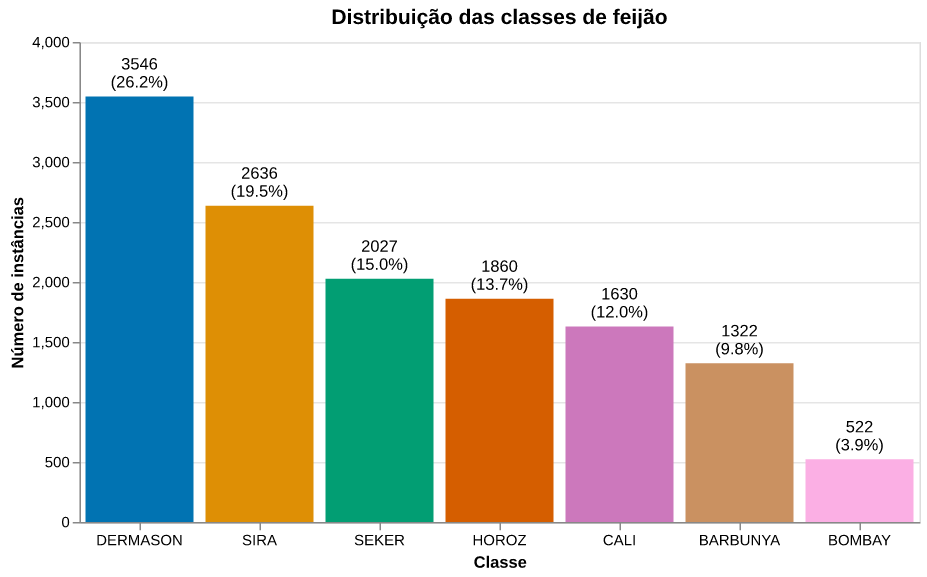

Classe majoritária: DERMASON (3546) | Classe minoritária: BOMBAY (522)
Razão entre as duas classes: 6.79


In [5]:
# Histograma da distribuição de classes
perc = df[TARGET].value_counts(normalize=True).mul(100).round(2)

df_cls = pd.DataFrame({
    TARGET: CLASS_ORDER,
    "count": [int(cont[c]) for c in CLASS_ORDER],
    "percentage": [f"({perc[c]:.1f}%)" for c in CLASS_ORDER],
})

base = alt.Chart(df_cls).encode(
            x = alt.X(f"{TARGET}:N", sort=CLASS_ORDER, title="Classe", axis=alt.Axis(labelAngle=0)),
            y = alt.Y("count:Q", title="Número de instâncias")
        )

bars = base.mark_bar().encode(color=class_color(legend=False))
labels_n = base.mark_text(baseline="bottom", dy=-16, fontSize=11).encode(text=alt.Text("count:Q", format="d"))
labels_p = base.mark_text(baseline="bottom", dy=-4, fontSize=11).encode(text="percentage:N")

hist_cls = (bars + labels_n + labels_p).properties(
    width=560, height=320, title="Distribuição das classes de feijão")
display(stylize(hist_cls))

ratio = cont.max() / cont.min()
print(f"Classe majoritária: {cont.idxmax()} ({cont.max()}) | Classe minoritária: {cont.idxmin()} ({cont.min()})")
print(f"Razão entre as duas classes: {ratio:.2f}")

A análise da distribuição da variável alvo mostra um desbalanceamento considerável, com a classe mais comum sendo quase 7 vezes mais frequente que a mais rara. Isso sugere que a acurácia não é a métrica mais adequada para um modelo. Alternativas como F1-score podem ser melhores.

### Análise das features numéricas

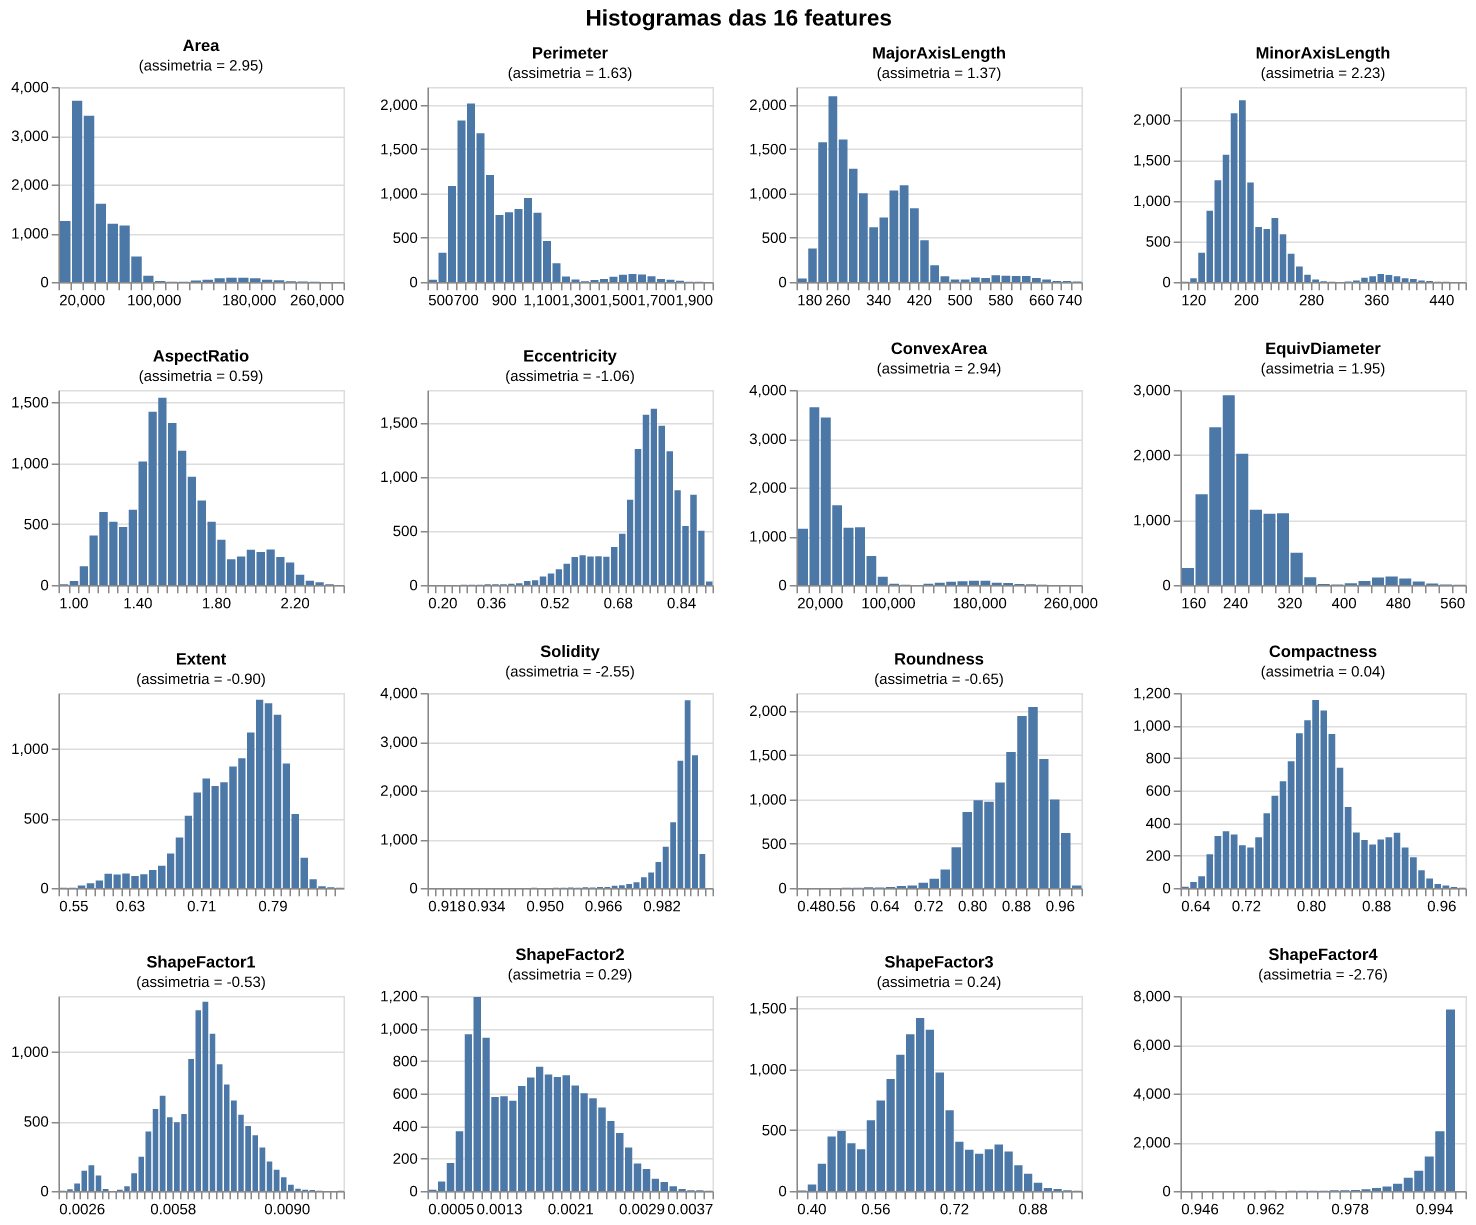

In [6]:
# Histogramas das features
def hist_feature(f):
    return (
        alt.Chart(df[[f]])
        .mark_bar()
        .encode(
            x = alt.X(f"{f}:Q", bin=alt.Bin(maxbins=40), title=None),
            y = alt.Y("count():Q", title=None)
        )
        .properties(
            width=190, height=130,
            title=alt.TitleParams(f, subtitle=f"(assimetria = {df[f].skew():.2f})",
                                  fontSize=11, subtitleFontSize=10)
        )
    )


all_hists = alt.concat(*[hist_feature(f) for f in FEATURES], columns=4).properties(
    title=alt.TitleParams("Histogramas das 16 features", fontSize=15, anchor="middle"))
display(all_hists)

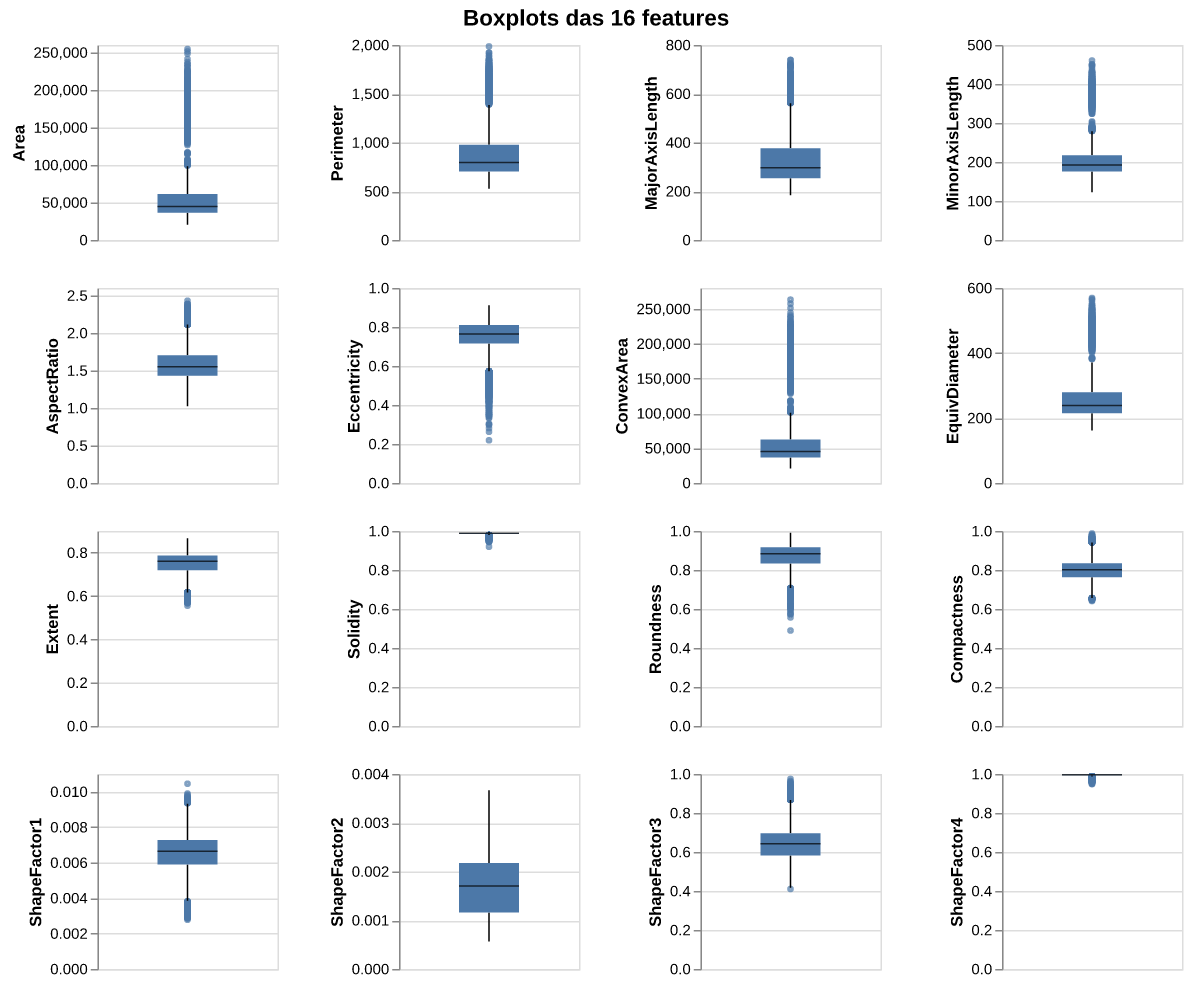

In [7]:
# Boxplots das features
box_plts = (
    alt.Chart(df[FEATURES])
    .mark_boxplot(extent=1.5, size=40,
                  median={"color": "black"}, outliers={"size": 6})
    .encode(y=alt.Y(alt.repeat("repeat"), type="quantitative"))
    .properties(width=120, height=130)
    .repeat(repeat=FEATURES, columns=4)
    .resolve_scale(y="independent")
    .properties(title=alt.TitleParams(
        "Boxplots das 16 features",
        fontSize=15, anchor="middle"))
)

display(box_plts)

Em todas as features relacionadas a tamanho, nota-se uma forte assimetria positiva. Ainda durante a análise de dados, vale verificar se isso acontece porque classes mais raras de feijão possuem grãos maiores.

As features Solidity e ShapeFactor4 possuem variância visivelmente baixa, fato que será reforçado em outras análises.

Além disso, muitas features mostram ter pelo menos dois picos. Logicamente, classes muito distintas de feijão concentram a distribuição delas em pontos específicos. Essas features podem ser especialmente úteis para predição.

In [8]:
# Tabela de estatísticas descritivas
stats = pd.DataFrame({
    "min": df[FEATURES].min(),
    "max": df[FEATURES].max(),
    "media": df[FEATURES].mean(),
    "desvio": df[FEATURES].std(),
    "assimetria": df[FEATURES].skew(),
})

stats["CV"] = stats["desvio"] / stats["media"]
print("Estatísticas descritivas:")
display(stats)

print(f"\nMaior desvio-padrão: {stats['desvio'].idxmax()} = {stats['desvio'].max():,.2f}")
print(f"Menor desvio-padrão: {stats['desvio'].idxmin()} = {stats['desvio'].min():,.6f}")
print(f"Razão entre maior e menor desvio: {stats['desvio'].max() / stats['desvio'].min():,.0f}")

Estatísticas descritivas:


,min,max,media,desvio,assimetria,CV
Area,20420.000000,254616.000000,53048.460385,29392.438324,2.947136,0.554068
Perimeter,524.736000,1985.370000,854.993406,214.722684,1.628018,0.251140
MajorAxisLength,183.601165,738.860154,319.895602,85.809260,1.365813,0.268241
MinorAxisLength,122.512653,460.198497,202.365321,45.051632,2.232013,0.222625
AspectRatio,1.024868,2.430306,1.581075,0.245245,0.589045,0.155113
Eccentricity,0.218951,0.911423,0.750315,0.091858,-1.064932,0.122426
ConvexArea,20684.000000,263261.000000,53767.986709,29844.248525,2.936102,0.555056
EquivDiameter,161.243764,569.374358,253.034094,59.307709,1.947303,0.234386
Extent,0.555315,0.866195,0.749829,0.048939,-0.895655,0.065267
Solidity,0.919246,0.994677,0.987152,0.004650,-2.546877,0.004711



Maior desvio-padrão: ConvexArea = 29,844.25
Menor desvio-padrão: ShapeFactor2 = 0.000595
Razão entre maior e menor desvio: 50,118,502


A tabela de estatísticas mostra uma diferença extrema nas ordens de grandeza entre as features. De fato, muitas features representam razões intrinsecamente limitadas ao intervalo [0, 1], enquanto outras como Area e ConvexArea são representadas por quantidades de pixels em fotos de alta resolução, atingindo a ordem de dezenas de milhares. A padronização se torna essencial.

In [9]:
# Outliers por feature
q1 = df[FEATURES].quantile(0.25)
q3 = df[FEATURES].quantile(0.75)
iqr = q3 - q1
outls = ((df[FEATURES] < q1 - 1.5 * iqr) | (df[FEATURES] > q3 + 1.5 * iqr)).sum() # Regra IQR
out_tab = pd.DataFrame({"Outliers": outls, "Porcentagem%": (outls / len(df) * 100).round(2)})
print("Outliers por feature:")
display(out_tab.sort_values("Outliers", ascending=False))

Outliers por feature:


,Outliers,Porcentagem%
Eccentricity,833,6.15
Solidity,774,5.72
ShapeFactor4,760,5.61
MinorAxisLength,567,4.19
Area,551,4.07
ConvexArea,549,4.05
ShapeFactor1,533,3.94
EquivDiameter,526,3.88
Perimeter,500,3.69
AspectRatio,485,3.58


### Relação entre features e alvo

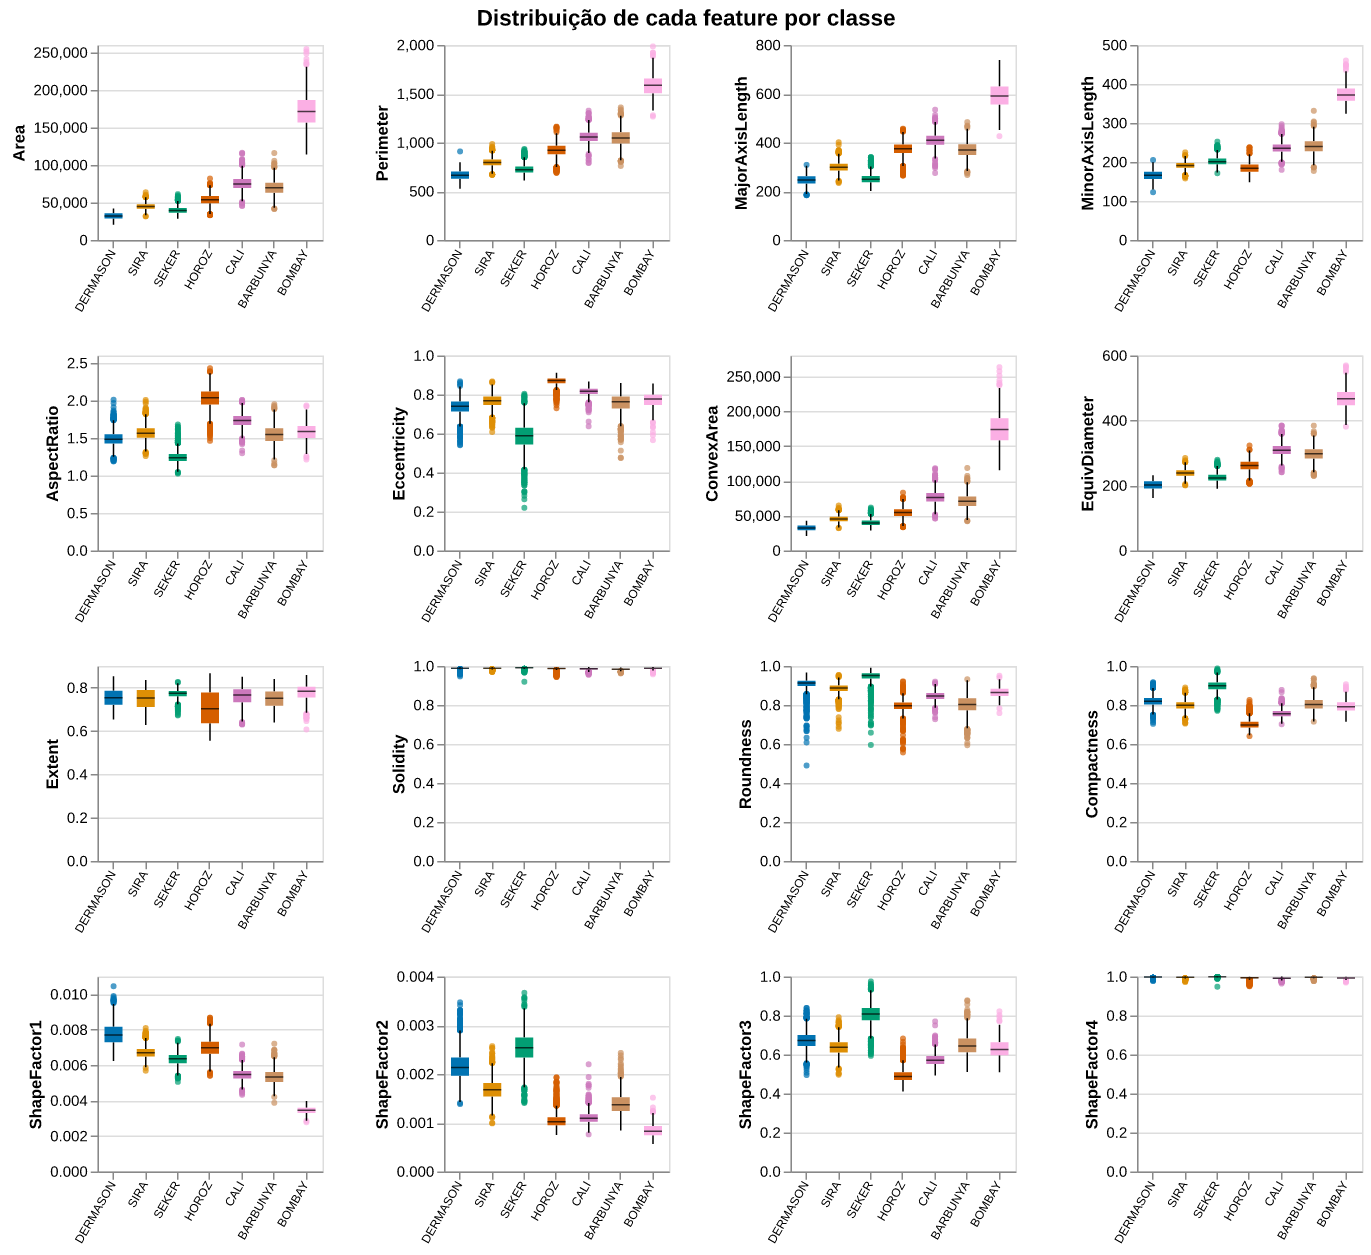

In [10]:
# Boxplots por classe
box_plts_cls = (
    alt.Chart(df[FEATURES + [TARGET]])
    .mark_boxplot(extent=1.5, size=12, median={"color": "black"}, outliers={"size": 4})
    .encode(
        x = alt.X(f"{TARGET}:N", sort=CLASS_ORDER, title=None,
                axis=alt.Axis(labelAngle=-60, labelFontSize=8)),
        y = alt.Y(alt.repeat("repeat"), type="quantitative"),
        color=class_color(legend=False)
    )
    .properties(width=150, height=130)
    .repeat(repeat=FEATURES, columns=4)
    .resolve_scale(y="independent")
    .properties(title=alt.TitleParams("Distribuição de cada feature por classe",
                                      fontSize=15, anchor="middle"))
)

display(box_plts_cls)

É razoável supor que algumas classes de feijão são muito diferentes em tamanho ou forma. Para testar essa hipótese, fizemos alguns gráficos de dispersão usando apenas pares de features dimensionais OU morfológicas escolhidos por intuição, e observamos como as classes se separam nesses gráficos:

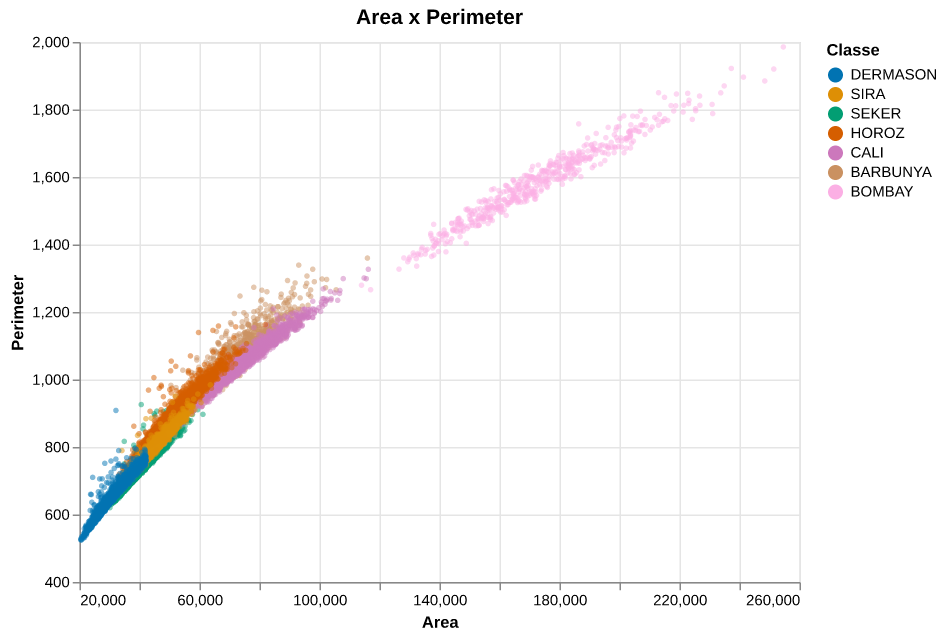

Correlação de Pearson entre Area e Perimeter: 0.967


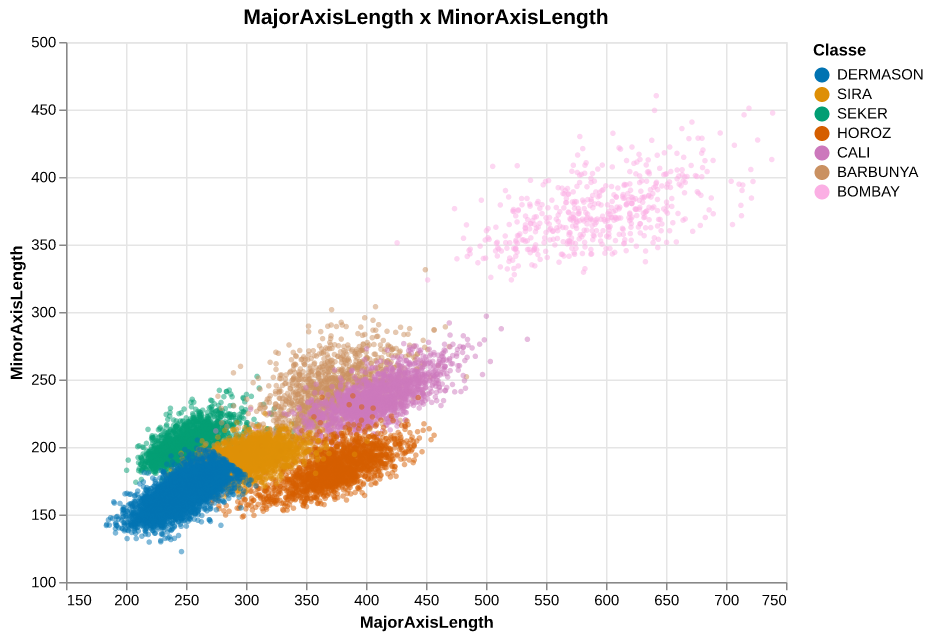

Correlação de Pearson entre MajorAxisLength e MinorAxisLength: 0.828


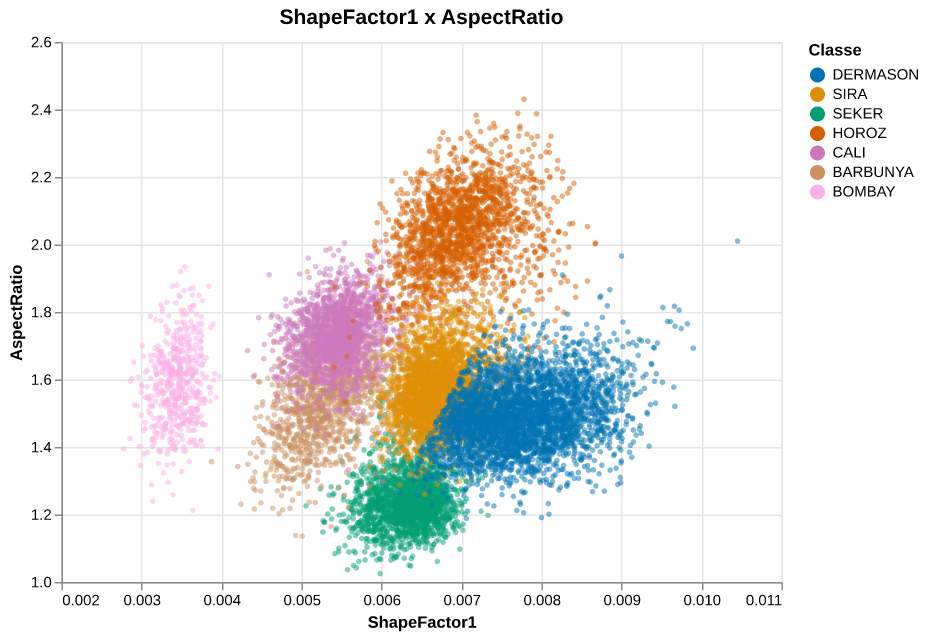

Correlação de Pearson entre ShapeFactor1 e AspectRatio: 0.021


In [11]:
# Alguns gráficos de dispersão especiais
PAIRS = [
    ("Area", "Perimeter"),
    ("MajorAxisLength", "MinorAxisLength"),
    ("ShapeFactor1", "AspectRatio")
]

for a, b in PAIRS:
    chart = (
        alt.Chart(df[[a, b, TARGET]])
        .mark_circle(size=14, opacity=0.5)
        .encode(
            x=alt.X(f"{a}:Q", scale=alt.Scale(zero=False)),
            y=alt.Y(f"{b}:Q", scale=alt.Scale(zero=False)),
            color=class_color(),
        )
        .properties(width=480, height=360, title=f"{a} x {b}")
    )
    display(stylize(chart))
    print(f"Correlação de Pearson entre {a} e {b}: {df[a].corr(df[b]):.3f}")

Eis o que podemos notar em cada gráfico:

*   **Gráfico 1:** Mesmo sem nenhum modelo, a classe Bombay é facilmente identificável nesse gráfico. Além disso, há uma relação quase linear entre Area e Perimeter (r = 0.97), mas a relação entre features será explorada mais tarde.
*   **Gráfico 2:** A correlação entre as features também existe, mas é mais fraca que no gráfico anterior (r = 0.83). Com menos redundância, a divisão entre as classes é mais clara, porém Bombay continua se destacando.
*   **Gráfico 3:** Essas features foram escolhidas por estarem entre as de maior CV mesmo sendo morfológicas. O que mais chama atenção é a semelhança com o gráfico 2, mostrando que features dimensionais e morfológicas carregam informação parecida.

Adicionalmente, notamos que nas 4 features relacionadas a tamanho a classe Bombay supera visivelmente as demais. Isso justifica as assimetrias positivas que observamos nessas features anteriormente, já que essa é a classe minoritária.

### Relações entre features

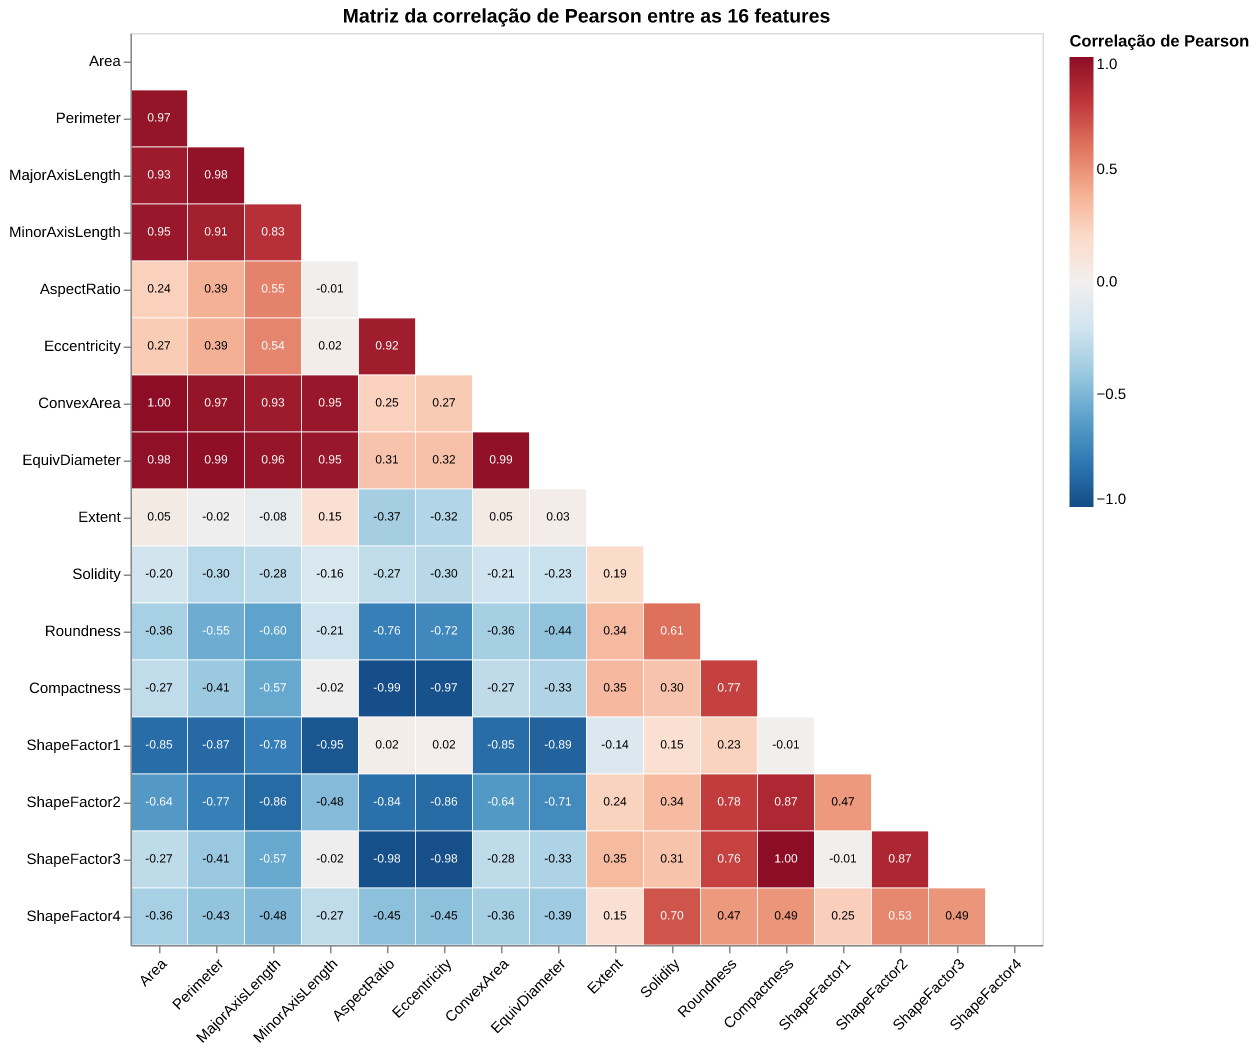

De 120 pares, 21 possuem |r| > 0.9:


,feature a,feature b,r,|r|
0,Area,ConvexArea,0.999940,0.999940
1,Compactness,ShapeFactor3,0.998684,0.998684
2,Perimeter,EquivDiameter,0.991453,0.991453
3,AspectRatio,Compactness,-0.987644,0.987644
4,ConvexArea,EquivDiameter,0.985255,0.985255
5,Area,EquivDiameter,0.984998,0.984998
6,Eccentricity,ShapeFactor3,-0.981058,0.981058
7,AspectRatio,ShapeFactor3,-0.978528,0.978528
8,Perimeter,MajorAxisLength,0.977561,0.977561
9,Eccentricity,Compactness,-0.970308,0.970308


In [12]:
# Matriz de correlação de Pearson
corr = df[FEATURES].corr(method="pearson")

pos = {f: i for i, f in enumerate(FEATURES)}
corr_long = (
    corr.rename_axis("feature a").reset_index()
    .melt(id_vars="feature a", var_name="feature b", value_name="r")
)
corr_long = corr_long[corr_long["feature a"].map(pos) > corr_long["feature b"].map(pos)]
corr_long["r_txt"] = corr_long["r"].map(lambda v: f"{v:.2f}")

base = alt.Chart(corr_long).encode(
    x=alt.X("feature b:N", scale=alt.Scale(domain=FEATURES), title=None, axis=alt.Axis(labelAngle=-45)),
    y=alt.Y("feature a:N", scale=alt.Scale(domain=FEATURES), title=None)
)

cells = base.mark_rect(stroke="white", strokeWidth=0.5).encode(
    color=alt.Color(
        "r:Q",
        scale=alt.Scale(scheme="redblue", reverse=True, domain=[-1, 1]),
        legend=alt.Legend(title="Correlação de Pearson", gradientLength=300)
    )
)

values = base.mark_text(fontSize=8).encode(
    text="r_txt:N",
    color=alt.condition("abs(datum.r) > 0.5", alt.value("white"), alt.value("black")),
)

corr_heatmap = (cells + values).properties(
    width=16 * 38, height=16 * 38,
    title="Matriz da correlação de Pearson entre as 16 features")
display(corr_heatmap)

idx_i, idx_j = np.triu_indices(len(FEATURES), k=1)
pairs = pd.DataFrame({
    "feature a": [FEATURES[i] for i in idx_i],
    "feature b": [FEATURES[j] for j in idx_j],
    "r": corr.values[idx_i, idx_j],
})
pairs["|r|"] = pairs["r"].abs()
highest = pairs[pairs["|r|"] > 0.9].sort_values("|r|", ascending=False).reset_index(drop=True)
print(f"De {len(pairs)} pares, {len(highest)} possuem |r| > 0.9:")
display(highest)

Temos um alerta importante: vários pares de features são fortemente correlacionados (21 dos 120 pares têm |r| > 0.9). É natural, uma vez que todas são relacionadas ao tamanho ou forma do grão.

Do ponto de vista de modelos que dependam da distância ou possuem alto custo computacional, isso significa que esse dataset possui uma dimensionalidade desnecessariamente alta. Também surge o problema da multicolinearidade, que afeta métodos lineares.

A implementação de métodos de redução de dimensionalidade, como o PCA, torna-se fortemente recomendada.

### Aprendizado não supervisionado

#### PCA

Como todas as features são numéricas, usamos todas para o PCA. Por padrão, normalizamos previamente.

In [13]:
FEATURES_CLS = FEATURES

X_cls = df[FEATURES_CLS].to_numpy(dtype=float)
Z_cls = normalize(X_cls)
pca_cls, S_cls, tab_pca_cls, var_exp_cls, var_acum_cls = fit_pca(Z_cls, FEATURES_CLS)

# Cargas e variância das 4 primeiras componentes
N_PCS = 4
display(tab_pca_cls.iloc[:, :N_PCS])

,PC1,PC2,PC3,PC4
Area,0.283,0.246,0.062,-0.032
Perimeter,0.311,0.179,0.018,-0.043
MajorAxisLength,0.326,0.101,0.085,-0.007
MinorAxisLength,0.237,0.343,-0.007,-0.062
AspectRatio,0.229,-0.331,0.169,0.053
Eccentricity,0.231,-0.320,0.164,0.119
ConvexArea,0.283,0.244,0.054,-0.031
EquivDiameter,0.297,0.223,0.050,-0.033
Extent,-0.060,0.222,0.086,0.947
Solidity,-0.143,0.104,0.739,-0.051


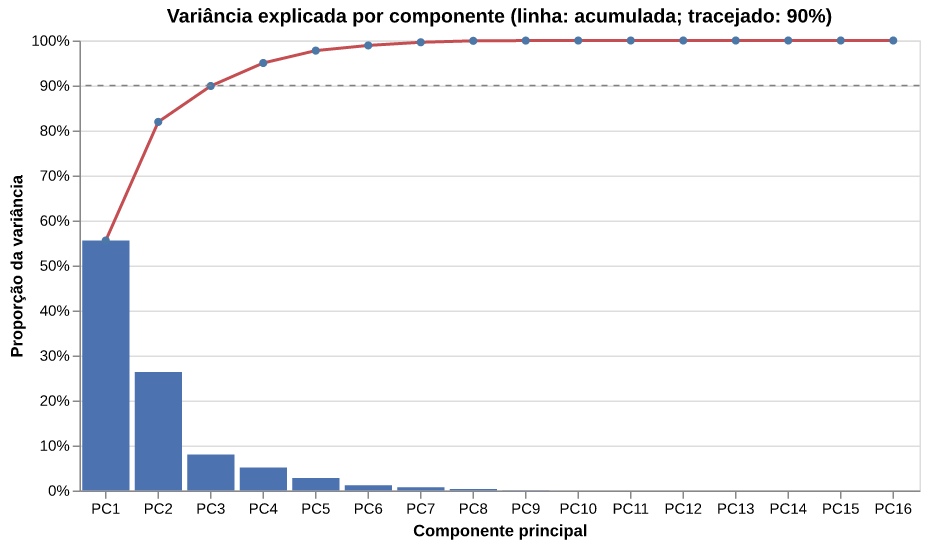

In [14]:
# Gráfico do cotovelo do PCA
display(pca_elbow_chart(var_exp_cls, var_acum_cls))

O PCA se mostra efetivo ao concentrar mais de 90% da variância em apenas 4 componentes (95.0%; com 3 componentes ficaríamos em 89.9%, um pouco abaixo da marca). Tomando essas 4 componentes, resolvemos o problema da alta dimensionalidade perdendo pouca informação.

Quanto às cargas, notamos que PC1 (55.5% da variância) favorece features associadas a tamanho, como MajorAxisLength e Perimeter. Já PC2 (26.4%) é alto para grãos arredondados e de baixa excentricidade: as cargas são positivas em MinorAxisLength, Compactness e ShapeFactor3 e negativas em AspectRatio e Eccentricity. As componentes PC3 e PC4 pesam apenas em features com CV baixo (Solidity e ShapeFactor4 em PC3, Extent em PC4), não tendo tanto significado.

#### K-means

Rodamos o K-means nos scores das 4 primeiras componentes principais, variando K de 2 a 10.

In [15]:
S_km = S_cls[:, :N_PCS]

models_cls, wss_cls, tab_wss_cls = sweep_k(S_km)
display(tab_wss_cls)

,K,WSS,queda (%)
0,2,118560.239548,NaN
1,3,84724.435555,28.5
2,4,71064.198116,16.1
3,5,53127.020193,25.2
4,6,46750.890069,12.0
5,7,43454.609618,7.1
6,8,42456.974948,2.3
7,9,36824.934482,13.3
8,10,34491.499524,6.3


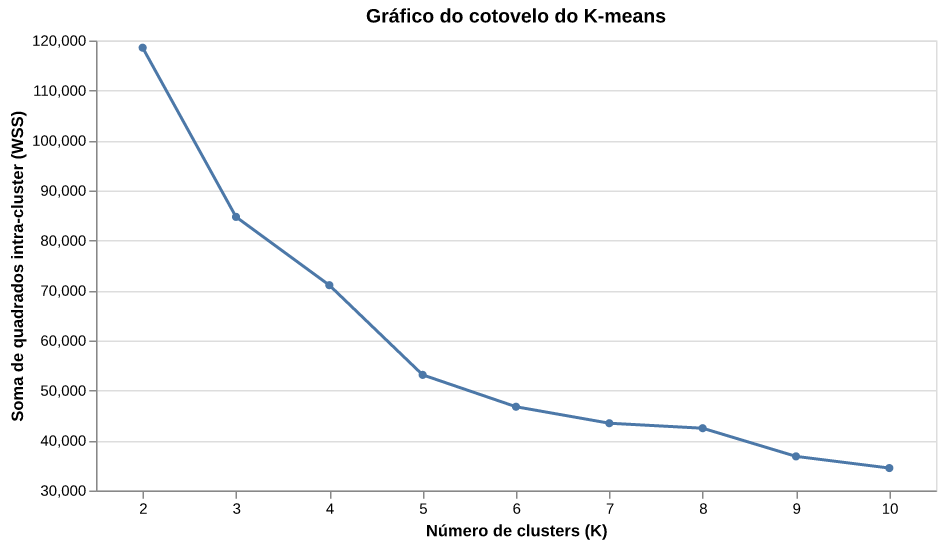

In [16]:
# Gráfico do cotovelo K-means
display(wss_chart(wss_cls))

Para a aplicação de KMeans, construímos o gráfico da WSS e argumentamos que é possível visualizar um cotovelo em K=5, justificando essa escolha de hiperparâmetro: de K=4 para K=5 a WSS ainda cai 25.2%, enquanto as quedas seguintes são bem menores (12.0% em K=6 e 7.1% em K=7). A curva não é perfeitamente suave (há outra queda de 13.3% em K=9), então a escolha tem um pouco de julgamento visual. Podemos analisar o perfil dos clusters pela proporção de classes:

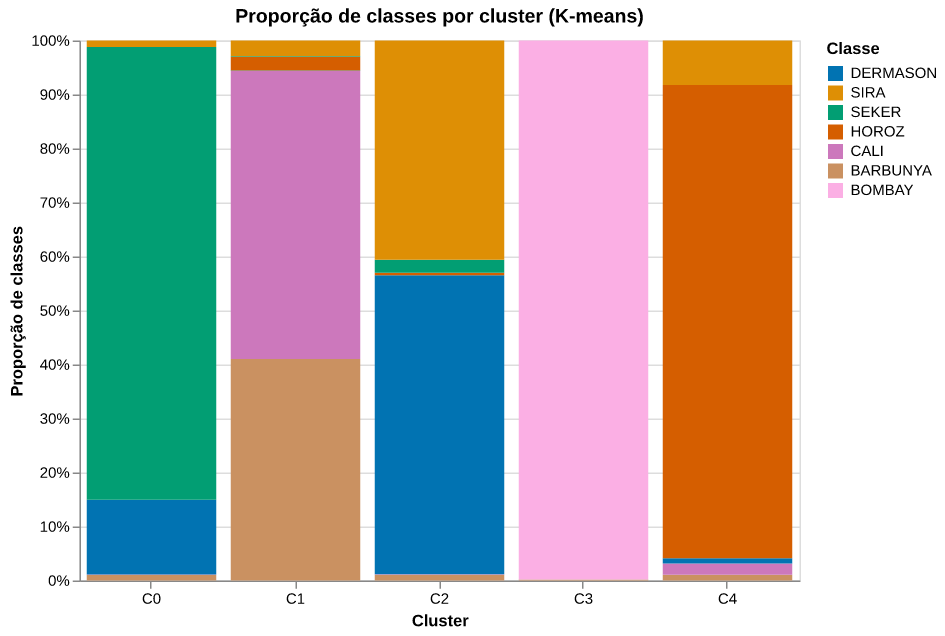

Class,BARBUNYA,BOMBAY,CALI,DERMASON,HOROZ,SEKER,SIRA
cluster,,,,,,,
C0,1.0,0.0,0.1,13.8,0.0,83.9,1.2
C1,41.0,0.0,53.3,0.1,2.5,0.1,2.9
C2,1.1,0.0,0.1,55.4,0.5,2.4,40.6
C3,0.2,99.8,0.0,0.0,0.0,0.0,0.0
C4,1.0,0.0,2.1,1.0,87.6,0.0,8.2


In [17]:
# Proporção de classes por cluster
K_CLS = 5
km_cls = KMeans(k=K_CLS, seed=SEED).fit(S_km)
cluster_labels = [f"C{i}" for i in range(K_CLS)]

df_cluster = pd.DataFrame({
    "cluster": [cluster_labels[c] for c in km_cls.labels],
    TARGET: df[TARGET].to_numpy(),
})

cluster_class_counts = (
    df_cluster.groupby(["cluster", TARGET])
    .size()
    .reset_index(name="count")
)

cluster_totals = cluster_class_counts.groupby("cluster")["count"].transform("sum")
cluster_class_counts["proportion"] = cluster_class_counts["count"] / cluster_totals

cluster_class_chart = (
    alt.Chart(cluster_class_counts)
    .mark_bar()
    .encode(
        x=alt.X("cluster:N", sort=cluster_labels, title="Cluster", axis=alt.Axis(labelAngle=0)),
        y=alt.Y("proportion:Q", title="Proporção de classes", axis=alt.Axis(format="%")),
        color=class_color(),
        order=alt.Order(f"{TARGET}:N", sort="ascending"),
    )
    .properties(
        width=480, height=360,
        title="Proporção de classes por cluster (K-means)"
    )
)

display(cluster_class_chart)

# Mesma informação em tabela (% de cada classe dentro do cluster)
display((pd.crosstab(df_cluster["cluster"], df_cluster[TARGET], normalize="index") * 100).round(1))

A escolha de K=5 gera uma configuração interessante: 3 dos 5 clusters são praticamente dominados por uma única classe (C0 é 83.9% Seker, C4 é 87.6% Horoz). Em especial, 99.8% do cluster C3 está na classe Bombay, que é a classe mais distinta. Por outro lado, Cali e Barbunya permanecem misturadas no cluster C1 (53.3% e 41.0%), e Dermason e Sira no cluster C2 (55.4% e 40.6%).

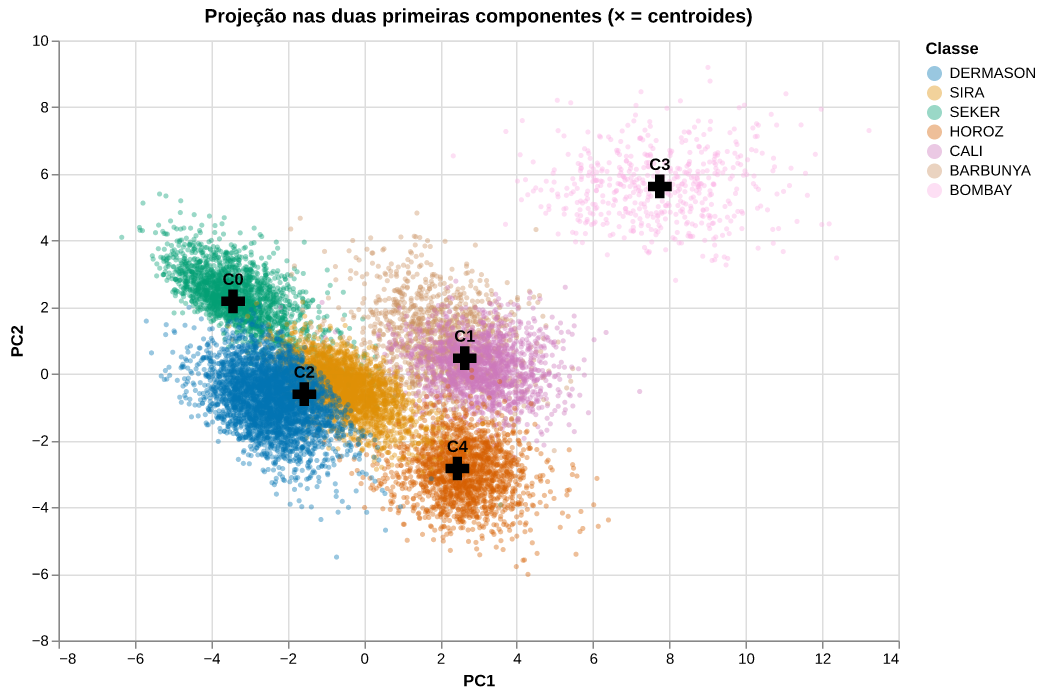

In [18]:
# Gráfico PCA + centroides
display(projection_chart(S_km, km_cls, (TARGET, df[TARGET].to_numpy(), class_color())))

Por fim, tentamos visualizar a dispersão das classes usando apenas 2 componentes principais. O resultado se assemelha aos gráficos de dispersão plotados antes.

Adicionando os centroides nessa visualização, percebemos que, de fato, as classes se concentram muito bem em 5 clusters. Ainda, como o número de classes é maior do que o de clusters, há fortes sobreposições em alguns pares: Dermason x Sira e Cali x Barbunya. Provavelmente serão os pares mais confundidos nos modelos de classificação.

### Verificação de plausibilidade dos dados e checagem de leakage

In [19]:
checks = {}
checks["Area > 0"] = (df["Area"] > 0).all()
checks["Perimeter > 0"] = (df["Perimeter"] > 0).all()
checks["MajorAxisLength >= MinorAxisLength"] = (df["MajorAxisLength"] >= df["MinorAxisLength"]).all()
checks["ConvexArea >= Area"] = (df["ConvexArea"] >= df["Area"]).all()
checks["AspectRatio >= 1"] = (df["AspectRatio"] >= 1).all()

checks["Eccentricity em [0, 1)"] = ((df["Eccentricity"] >= 0) & (df["Eccentricity"] < 1)).all()

# Razões que devem estar em (0, 1].
ratios01 = ["Extent", "Solidity", "Roundness",
             "Compactness", "ShapeFactor3", "ShapeFactor4"]

for f in ratios01:
    checks[f"{f} em (0, 1]"] = ((df[f] > 0) & (df[f] <= 1)).all()

checks_df = pd.DataFrame({"Passou?": pd.Series(checks)})
display(checks_df)

if checks_df["Passou?"].all():
    print("Todas as checagens passaram!")
else:
    failures = (~checks_df["Passou?"]).sum()
    print(f"Total de checagens falhas: {failures}")

,Passou?
Area > 0,True
Perimeter > 0,True
MajorAxisLength >= MinorAxisLength,True
ConvexArea >= Area,True
AspectRatio >= 1,True
"Eccentricity em [0, 1)",True
"Extent em (0, 1]",True
"Solidity em (0, 1]",True
"Roundness em (0, 1]",True
"Compactness em (0, 1]",True


Todas as checagens passaram!


Acima, uma bateria de checagens que verifica a plausibilidade lógica dos dados. Não houve problema em nenhuma das checagens. No mais, devemos comentar que nenhuma das features é derivada do tipo do grão, portanto o risco de leakage só existe no caso de uma má divisão dos dados ao treinar os modelos.